<center><h1>Jha_Ria_HW3</h1></center>
<br>
<br>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Time Series Classification Part 1: Feature Creation/Extraction


### (a) Download Data


Package imports


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import f_classif

Get the AReM Data Set


In [2]:
BASE = "AReM"
cols = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
issues = []

def load_file(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t != ""]
            if len(tokens) != 7:
                issues.append((path, len(tokens), line[:60]))
            if len(tokens) < 7:
                continue
            try:
                rows.append([float(t) for t in tokens[1:7]])
            except ValueError:
                issues.append((path, "non-numeric", line[:60]))
    return pd.DataFrame(rows, columns=cols)

records = []
for activity in sorted(os.listdir(BASE)):
    folder = os.path.join(BASE, activity)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        if not fname.endswith(".csv"):
            continue
        num = int(re.findall(r"\d+", fname)[0])
        test_ids = (1, 2) if activity in ("bending1", "bending2") else (1, 2, 3)
        records.append({
            "activity": activity,
            "num": num,
            "is_test": num in test_ids,
            "data": load_file(os.path.join(folder, fname)),
        })

print(len(records))
print({r["data"].shape for r in records})
for i in issues:
    print(i)

88
{(479, 6), (480, 6)}


In [3]:
print([(r["activity"], r["num"], r["data"].shape[0]) for r in records if r["data"].shape[0] != 480])

[('sitting', 8, 479)]


Note: sitting dataset 8 contains 479 rows instead of 480 in the raw file. Since the features are summary statistics, this does not affect the analysis. Some files also had stray trailing separators, which the loader skips.


### (b) Test and Train Data


Datasets 1 and 2 in folders bending1 and bending2, and datasets 1, 2 and 3 in all other folders, are the test data. All other datasets are the train data.


In [4]:
print("test instances:", sum(r["is_test"] for r in records), "| train instances:", sum(not r["is_test"] for r in records))

test instances: 19 | train instances: 69


### (c) Feature Extraction


#### i. Research


- Location: minimum, maximum, mean, median, first quartile, third quartile
- Spread: standard deviation, variance, range, interquartile range (IQR)
- Shape: skewness, kurtosis
- Energy and magnitude: root mean square (RMS), mean absolute value, sum of squares
- Dynamics: zero-crossing rate, number of peaks, mean absolute change between consecutive points, autocorrelation at lag 1


#### ii. Extraction


In [5]:
# Feature extraction

stat_funcs = {
    "min": lambda s: s.min(),
    "max": lambda s: s.max(),
    "mean": lambda s: s.mean(),
    "median": lambda s: s.median(),
    "std": lambda s: s.std(),
    "q1": lambda s: s.quantile(0.25),
    "q3": lambda s: s.quantile(0.75),
}

def extract_features(df):
    feats = {}
    for i, col in enumerate(df.columns, start=1):
        for name, f in stat_funcs.items():
            feats[f"{name}{i}"] = f(df[col])
    return feats

rows = []
for r in records:
    row = extract_features(r["data"])
    row["activity"] = r["activity"]
    row["num"] = r["num"]
    row["is_test"] = r["is_test"]
    rows.append(row)

features = pd.DataFrame(rows)
feature_cols = [c for c in features.columns if c not in ("activity", "num", "is_test")]

train = features[~features.is_test].reset_index(drop=True)
test = features[features.is_test].reset_index(drop=True)

print(features.shape, train.shape, test.shape)
features[feature_cols].head()

(88, 45) (69, 45) (19, 45)


,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### iii. Standard Deviation


In [6]:
# Standard deviation and 90% bootstrap CI

rng = np.random.default_rng(42)
B = 2000

def bootstrap_std_ci(x, B=B, alpha=0.10):
    x = np.asarray(x)
    n = len(x)
    idx = rng.integers(0, n, size=(B, n))
    boot_stds = x[idx].std(axis=1, ddof=1)
    lo, hi = np.percentile(boot_stds, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return lo, hi

ci_rows = []
for c in feature_cols:
    lo, hi = bootstrap_std_ci(features[c])
    ci_rows.append({"feature": c, "std": features[c].std(), "ci_lo": lo, "ci_hi": hi})

ci_table = pd.DataFrame(ci_rows).set_index("feature")
ci_table["inside"] = (ci_table["std"] >= ci_table["ci_lo"]) & (ci_table["std"] <= ci_table["ci_hi"])

print(ci_table["inside"].all())
ci_table.round(3)

True


,std,ci_lo,ci_hi,inside
feature,,,,
min1,9.570,8.227,10.783,True
max1,4.394,3.325,5.262,True
mean1,5.336,4.696,5.906,True
median1,5.440,4.834,6.005,True
std1,1.772,1.572,1.963,True
q11,6.154,5.585,6.637,True
q31,5.139,4.334,5.840,True
min2,0.000,0.000,0.000,True
max2,5.063,4.635,5.415,True


For each of the 42 features I computed the sample standard deviation across all 88 instances, then built a 90% bootstrap CI by resampling the 88 instances with replacement 2000 times, recomputing the std each time, and taking the 5th and 95th percentiles.

Observations: min1 has the largest spread (std 9.57, CI [8.23, 10.78]), followed by q11, min5, q15 and mean5 (std about 5.7 to 6.2), which also have the widest intervals. min2 and min4 are 0 for every instance (std 0, CI [0, 0]) and min6 is almost constant (std 0.046, CI [0, 0.078]), so these carry no information. In contrast, mean, std and quartile features of series 2, 4 and 6 have tight intervals (e.g. std2: 0.884, CI [0.805, 0.941]), meaning their variability across instances is estimated reliably.


#### iv. Select Features


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [ 7 21] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,F,p
mean2,900.156,0.0
q32,807.049,0.0
median4,800.795,0.0
q36,664.776,0.0
mean4,651.761,0.0
mean6,581.453,0.0
median6,563.125,0.0
q34,561.899,0.0
median2,477.013,0.0
std2,360.895,0.0


activity,bending1,bending2,cycling,lying,sitting,standing,walking
min1,34.85,23.12,24.22,33.50,34.87,34.96,19.62
max1,47.38,44.00,44.40,42.87,45.82,47.13,46.56
mean1,43.05,31.12,36.62,39.82,41.06,43.97,34.51
median1,43.47,30.43,36.18,38.81,40.56,44.42,35.12
std1,2.10,4.98,3.84,1.78,2.27,2.08,4.73
q11,41.86,27.36,33.89,38.56,39.21,42.97,31.34
q31,44.48,33.65,39.79,41.64,43.13,45.52,37.93
min2,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max2,2.12,5.92,10.84,2.61,3.24,2.85,14.08
mean2,0.49,0.41,2.79,0.39,0.42,0.38,4.37


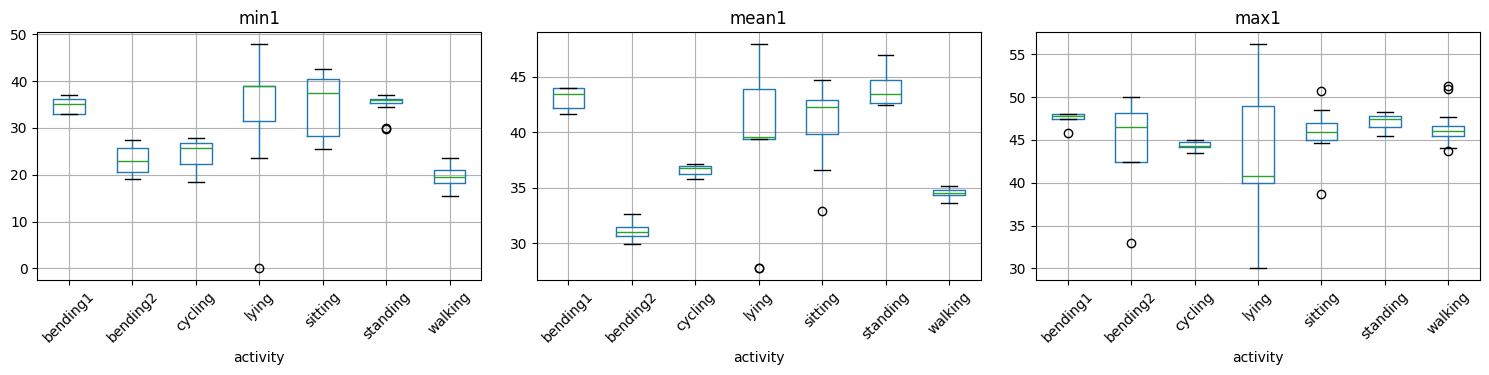

       min1  mean1  max1
min1   1.00   0.72  0.19
mean1  0.72   1.00  0.55
max1   0.19   0.55  1.00


In [7]:
F, p = f_classif(train[feature_cols], train["activity"])
ranking = pd.DataFrame({"F": F, "p": p}, index=feature_cols).sort_values("F", ascending=False)
display(ranking.head(15).round(3))

summary = train.groupby("activity")[feature_cols].mean()
display(summary.T.round(2))

candidates = ["min1", "mean1", "max1"]

fig, axes = plt.subplots(1, len(candidates), figsize=(5 * len(candidates), 4))
for ax, c in zip(axes, candidates):
    train.boxplot(column=c, by="activity", ax=ax, rot=45)
    ax.set_title(c)
plt.suptitle("")
plt.tight_layout()
plt.show()

print(train[candidates].corr().round(2))

**Selected features: min1, mean1, max1**

I selected the minimum, mean and maximum of series 1 (avg_rss12).

- Min and mean separate several activities. Walking (min1 19.6), bending2 (23.1) and cycling (24.2) have much lower minimums than the other activities (about 33 to 35). Mean1 is lowest for bending2 (31.1), walking (34.5) and cycling (36.6), versus about 40 to 44 for the rest.
- Max1 is the weakest separator (class means range only from 42.9 to 47.4), but it captures the upper end of the signal and is the least correlated with the others.
- The three are not redundant: correlations are 0.72 (min, mean), 0.55 (mean, max) and 0.19 (min, max).
- Their bootstrap CIs are reasonably tight, so their spread across instances is estimated reliably (min1 std 9.57, CI [8.23, 10.78]; mean1 std 5.34, CI [4.70, 5.91]; max1 std 4.39, CI [3.33, 5.26]).

Lying and sitting have wide spreads that overlap with several other activities, so these three features alone will not separate every class.


## 2. ISLR 3.7.4


### (a) Linear Train


I expect the cubic regression to have the lower training RSS. Least squares chooses the coefficients that minimize RSS on the training data, and the cubic model contains the linear model as a special case (set the X^2 and X^3 coefficients to zero). So the cubic fit can never do worse than the linear fit on the training set, and in practice it does strictly better because the extra terms bend the curve toward the random noise in the training points. Even though the true relationship is linear, this gain comes only from fitting noise, not from capturing real structure.


### (b) Linear Test


I expect the linear regression to have the lower test RSS. The true relationship is linear, so the linear model has little or no bias, and the cubic model has no bias left to remove, so its extra flexibility buys nothing. What it adds is variance: the X^2 and X^3 terms were tuned to noise in the training set, so on new data the cubic curve wiggles away from the true line and makes larger errors. This is overfitting: the training RSS went down, but the test RSS goes up.


### (c) Not Linear Train


The cubic regression again has the lower training RSS, whatever the true relationship is. The argument from (a) does not depend on the truth, only on the models being nested: the cubic model can reproduce any linear fit, so its minimum training RSS is always less than or equal to the linear model's. When the truth is not linear, the cubic model also captures some real curvature and not just noise, so the gap in training RSS is typically even larger than in (a).


### (d) Not Linear Testing


There is not enough information to tell, because it depends on how far the true relationship is from linear. If it is close to linear (only mild curvature), the cubic model's extra variance outweighs the small bias it removes, so the linear model has the lower test RSS, as in (b). If it is strongly curved and close to cubic, the linear model has high bias that more data cannot fix, so the cubic model has the lower test RSS. In short, test RSS is a bias-variance trade-off, and the cubic model wins only when the bias it removes is larger than the variance it adds.
